# TV3 — Tuần 2: Huấn luyện 6 Cấu hình Thực nghiệm `M2: 3D Attention U-Net`

Notebook này thực thi trọn vẹn công việc **Tuần 2 của TV3** theo `docs/task_assignment.md` và `docs/detailed_pipeline.md`, bao gồm **6 cấu hình (`Run 07` $\rightarrow$ `Run 12`)**:

| Run ID | Tên thư mục Checkpoint | Kiến trúc | Đầu vào (`ip_mode`) | Số kênh | Điều kiện hóa Subtype (`FiLM`) |
| :--- | :--- | :--- | :--- | :---: | :--- |
| **Run 07** | `run07_M2_IP1_post1_no_film` | `M2: 3D Attention U-Net` | `IP1_post1` ($C_1$: Post-contrast) | 1 | Không (`use_film=False`) |
| **Run 08** | `run08_M2_IP1_post1_film` | `M2: 3D Attention U-Net` | `IP1_post1` ($C_1$: Post-contrast) | 1 | Có (`MultiStageFiLM`) |
| **Run 09** | `run09_M2_IP2_sub_no_film` | `M2: 3D Attention U-Net` | `IP2_sub` ($C_2$: Subtraction) | 1 | Không (`use_film=False`) |
| **Run 10** | `run10_M2_IP2_sub_film` | `M2: 3D Attention U-Net` | `IP2_sub` ($C_2$: Subtraction) | 1 | Có (`MultiStageFiLM`) |
| **Run 11** | `run11_M2_IP3_multi_no_film` | `M2: 3D Attention U-Net` | `IP3_multi` ($C_1 + C_2 + C_3$) | 3 | Không (`use_film=False`) |
| **Run 12** | `run12_M2_IP3_multi_film` | `M2: 3D Attention U-Net` | `IP3_multi` ($C_1 + C_2 + C_3$) | 3 | Có (`MultiStageFiLM`) |

### Cấu trúc thư mục trên Google Drive (`CS406-IPA/`)
Thư mục trên Google Drive của bạn (`/content/drive/My Drive/CS406-IPA/`) có cấu trúc **giống hệt** thư mục `SCB-TumorSeg/` dưới máy tính cá nhân:
- `configs/default_config.yaml`
- `src/` (`datasets/`, `models/`, `losses/`, `engine/`, `utils/`, `preprocessing/`)
- `scripts/train_tv3_week2.py`
- `notebooks/TV3_Week2_AttentionUNet_6Runs.ipynb`
- `data/splits/splits_metadata.csv` & `data/processed/npz_96x96x96/` (1.480 files `.npz`)
- `outputs/` $\rightarrow$ Nơi lưu tự động `checkpoints/tv3_week2/`, `tables/tv3_week2_ablation_summary.csv` và `figures/tv3_week2_learning_curves.png`. Khi chạy xong, bạn chỉ cần tải thư mục `outputs/` về đặt vào đúng `SCB-TumorSeg/outputs/` dưới máy.

In [1]:
# 1. Mount Google Drive, chuyển vào thư mục CS406-IPA và cài đặt thư viện cần thiết
import os
import sys
from pathlib import Path

IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive", force_remount=False)
    PROJECT_ROOT = Path("/content/drive/My Drive/CS406-IPA")
    os.chdir(PROJECT_ROOT)
    %pip install -q monai nibabel SimpleITK scikit-image pyyaml tqdm pandas matplotlib
else:
    PROJECT_ROOT = next(
        (p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src/models/factory.py").is_file()),
        Path.cwd(),
    )
    os.chdir(PROJECT_ROOT)

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

print("Working Directory (PROJECT_ROOT):", PROJECT_ROOT)

Mounted at /content/drive
Working Directory (PROJECT_ROOT): /content/drive/My Drive/CS406-IPA


In [2]:
# 2. [TỐI ƯU TỐC ĐỘ COLAB] Copy 1.480 file .npz từ Google Drive sang ổ SSD cục bộ của máy ảo Colab
# Đọc 1.480 file qua mạng Google Drive FUSE mỗi epoch sẽ rất chậm. Copy 1 lần sang /content/local_npz_96x96x96
# chỉ mất ~1-2 phút nhưng giúp tốc độ train nhanh gấp ~10 lần. Kết quả outputs/ vẫn lưu thẳng về Google Drive!
import shutil
from concurrent.futures import ThreadPoolExecutor

DRIVE_NPZ_DIR = PROJECT_ROOT / "data" / "processed" / "npz_96x96x96"
METADATA_CSV = PROJECT_ROOT / "data" / "splits" / "splits_metadata.csv"
OUTPUT_ROOT = PROJECT_ROOT / "outputs"

USE_LOCAL_SSD_CACHE = True  # Đặt True trên Colab để copy .npz sang SSD cục bộ /content/

if IN_COLAB and USE_LOCAL_SSD_CACHE:
    LOCAL_NPZ_DIR = Path("/content/local_npz_96x96x96")
    LOCAL_NPZ_DIR.mkdir(parents=True, exist_ok=True)
    src_files = sorted(DRIVE_NPZ_DIR.glob("*.npz"))
    missing_files = [f for f in src_files if not (LOCAL_NPZ_DIR / f.name).is_file()]
    if missing_files:
        print(f"Đang copy {len(missing_files)}/{len(src_files)} file .npz từ Drive sang SSD cục bộ Colab...")
        def _copy_one(src_path: Path):
            shutil.copy2(src_path, LOCAL_NPZ_DIR / src_path.name)
        with ThreadPoolExecutor(max_workers=8) as ex:
            list(ex.map(_copy_one, missing_files))
    NPZ_DIR = LOCAL_NPZ_DIR
    print(f"Hoàn tất! Đang sử dụng {len(list(NPZ_DIR.glob('*.npz')))} file .npz tại SSD cục bộ: {NPZ_DIR}")
else:
    NPZ_DIR = DRIVE_NPZ_DIR
    print(f"Đang sử dụng {len(list(NPZ_DIR.glob('*.npz')))} file .npz trực tiếp tại: {NPZ_DIR}")

Đang copy 1480/1480 file .npz từ Drive sang SSD cục bộ Colab...
Hoàn tất! Đang sử dụng 1480 file .npz tại SSD cục bộ: /content/local_npz_96x96x96


In [3]:
# 3. Kiểm tra phần cứng GPU & Hợp đồng dữ liệu trước khi chạy
import pandas as pd
import torch
import monai

print("PyTorch:", torch.__version__, "| MONAI:", monai.__version__)
print("CUDA available:", torch.cuda.is_available())
if torch.cuda.is_available():
    print("GPU Device:", torch.cuda.get_device_name(0))
    print("VRAM (GB):", round(torch.cuda.get_device_properties(0).total_memory / (1024 ** 3), 2))
    print("BF16 supported:", torch.cuda.is_bf16_supported())

df_meta = pd.read_csv(METADATA_CSV)
print(f"\nTổng số ca trong splits_metadata.csv: {len(df_meta)}")
print(df_meta.groupby(["split", "tumor_subtype"]).size().unstack(fill_value=0))

PyTorch: 2.14.1+cu130 | MONAI: 1.6.1
CUDA available: True
GPU Device: NVIDIA A100-SXM4-40GB
VRAM (GB): 39.49
BF16 supported: True

Tổng số ca trong splits_metadata.csv: 1480
tumor_subtype  HER2-enriched  HER2-pure  Luminal  Triple Negative
split                                                            
test                      43         21      144               92
train                    107         37      513              346
val                       19          7       90               61


In [4]:
# 4. Cấu hình tham số huấn luyện trên GPU A100
SELECTED_RUNS = ["all"]

EPOCHS = 90
WARMUP_EPOCHS = 5
EARLY_STOPPING_PATIENCE = 25      # Kiên nhẫn 25 epochs sau khi qua ngưỡng fine-tuning
EARLY_STOPPING_MIN_EPOCHS = 45    # Chỉ bắt đầu đếm Early Stopping từ Epoch 46 (khi Cosine LR < 50% đỉnh)
SAVE_LAST_EVERY = 20

BATCH_SIZE = 16
SW_BATCH_SIZE = 8
SW_OVERLAP = 0.25                 # Overlap 0.25 lúc validate giữa kỳ giúp tăng tốc ~3.4x cho 22 ca VOI > 96^3
SAMPLER_POWER = 0.5               # Căn bậc hai trọng số (w^0.5): cân bằng Subtype mà không làm lệch phân phối ISPY2/Luminal

LR = 3e-4
WEIGHT_DECAY = 1e-5
USE_AMP = True
NUM_WORKERS = 4                   # Kết hợp persistent_workers=True giữ nguyên 4 workers xuyên suốt các epochs
CACHE_RATE = 1.0                  # Nạp 1 lần vào RAM 83.5GB Colab
RESUME = True
SEED = 42

print(f"Config: BATCH_SIZE={BATCH_SIZE}, EPOCHS={EPOCHS}, PATIENCE={EARLY_STOPPING_PATIENCE} (min_ep={EARLY_STOPPING_MIN_EPOCHS}), SAMPLER_POWER={SAMPLER_POWER}, NUM_WORKERS={NUM_WORKERS}, CACHE_RATE={CACHE_RATE}")


Config: BATCH_SIZE=16, EPOCHS=120, PATIENCE=20, NUM_WORKERS=4, CACHE_RATE=1.0


In [5]:
# 5. Thực thi huấn luyện 6 cấu hình M2 (3D Attention U-Net)
from scripts.train_tv3_week2 import run_tv3_week2_suite

summary_df = run_tv3_week2_suite(
    metadata_csv=METADATA_CSV,
    npz_dir=NPZ_DIR,
    output_root=OUTPUT_ROOT,
    config_path=PROJECT_ROOT / "configs" / "default_config.yaml",
    selected_runs=SELECTED_RUNS,
    epochs=EPOCHS,
    warmup_epochs=WARMUP_EPOCHS,
    batch_size=BATCH_SIZE,
    lr=LR,
    weight_decay=WEIGHT_DECAY,
    patch_size=(96, 96, 96),
    sw_batch_size=SW_BATCH_SIZE,
    sw_overlap=SW_OVERLAP,
    num_workers=NUM_WORKERS,
    cache_rate=CACHE_RATE,
    use_amp=USE_AMP,
    use_weighted_sampler=True,
    sampler_power=SAMPLER_POWER,
    save_last_every=SAVE_LAST_EVERY,
    early_stopping_patience=EARLY_STOPPING_PATIENCE,
    early_stopping_min_epochs=EARLY_STOPPING_MIN_EPOCHS,
    resume=RESUME,
    seed=SEED,
)

TV3 WEEK 2 — 3D ATTENTION U-NET (M2) ABLATION SUITE (6 RUNS)
  Device                 : cuda (NVIDIA A100-SXM4-40GB)
  Metadata CSV           : /content/drive/My Drive/CS406-IPA/data/splits/splits_metadata.csv
  NPZ Directory          : /content/local_npz_96x96x96
  Checkpoints Root       : /content/drive/My Drive/CS406-IPA/outputs/checkpoints/tv3_week2
  Epochs / Warmup        : 120 / 5
  Early Stopping Patience: 20
  Save last.pt Every     : 20 epochs (single file overwrite)
  Batch Size / LR / WD   : 16 / 0.0003 / 1e-05
  Patch Size / SW Batch  : (96, 96, 96) / 8 (overlap=0.5)
  WeightedRandomSampler  : True | Cache Rate: 1.0

[1/6] >>> Preparing run07_M2_IP1_post1_no_film (3D Attention U-Net | IP1 (Post-1) | No FiLM)
Building DataLoaders for ip_mode=IP1_post1 (channels=[0])...
Epoch 1/120 (52.2s) | train_loss=2.1901 | val_loss=1.1595 | val_dice=0.5864 | best=0.5864 (ep 1)
Epoch 2/120 (49.4s) | train_loss=1.8132 | val_loss=1.0660 | val_dice=0.5104 | best=0.5864 (ep 1)
Epoch 3/120 (4

,run_id,run_name,arch,ip_mode,in_channels,use_film,epochs_trained,best_epoch,best_val_dice,best_val_loss,train_dice_at_best,train_loss_at_best,final_train_loss,final_train_dice,final_val_loss,final_val_dice,completed,stopped_early,best_ckpt_exists
0,run07,run07_M2_IP1_post1_no_film,M2,IP1_post1,1,False,80,60,0.850803,0.171868,0.854508,0.318357,0.290180,0.867446,0.175000,0.847956,True,True,True
1,run08,run08_M2_IP1_post1_film,M2,IP1_post1,1,True,80,60,0.848589,0.174666,0.849711,0.326003,0.288419,0.866521,0.179235,0.844780,True,True,True
2,run09,run09_M2_IP2_sub_no_film,M2,IP2_sub,1,False,76,56,0.837256,0.188712,0.841986,0.335364,0.304804,0.855862,0.196649,0.830620,True,True,True
3,run10,run10_M2_IP2_sub_film,M2,IP2_sub,1,True,44,24,0.832338,0.196310,0.823302,0.388799,0.363018,0.832772,0.198986,0.830237,True,True,True
4,run11,run11_M2_IP3_multi_no_film,M2,IP3_multi,3,False,77,57,0.853063,0.170051,0.858041,0.305379,0.273033,0.871777,0.174791,0.849076,True,True,True
5,run12,run12_M2_IP3_multi_film,M2,IP3_multi,3,True,59,39,0.850749,0.172972,0.844758,0.336603,0.284800,0.865863,0.172972,0.850176,True,True,True


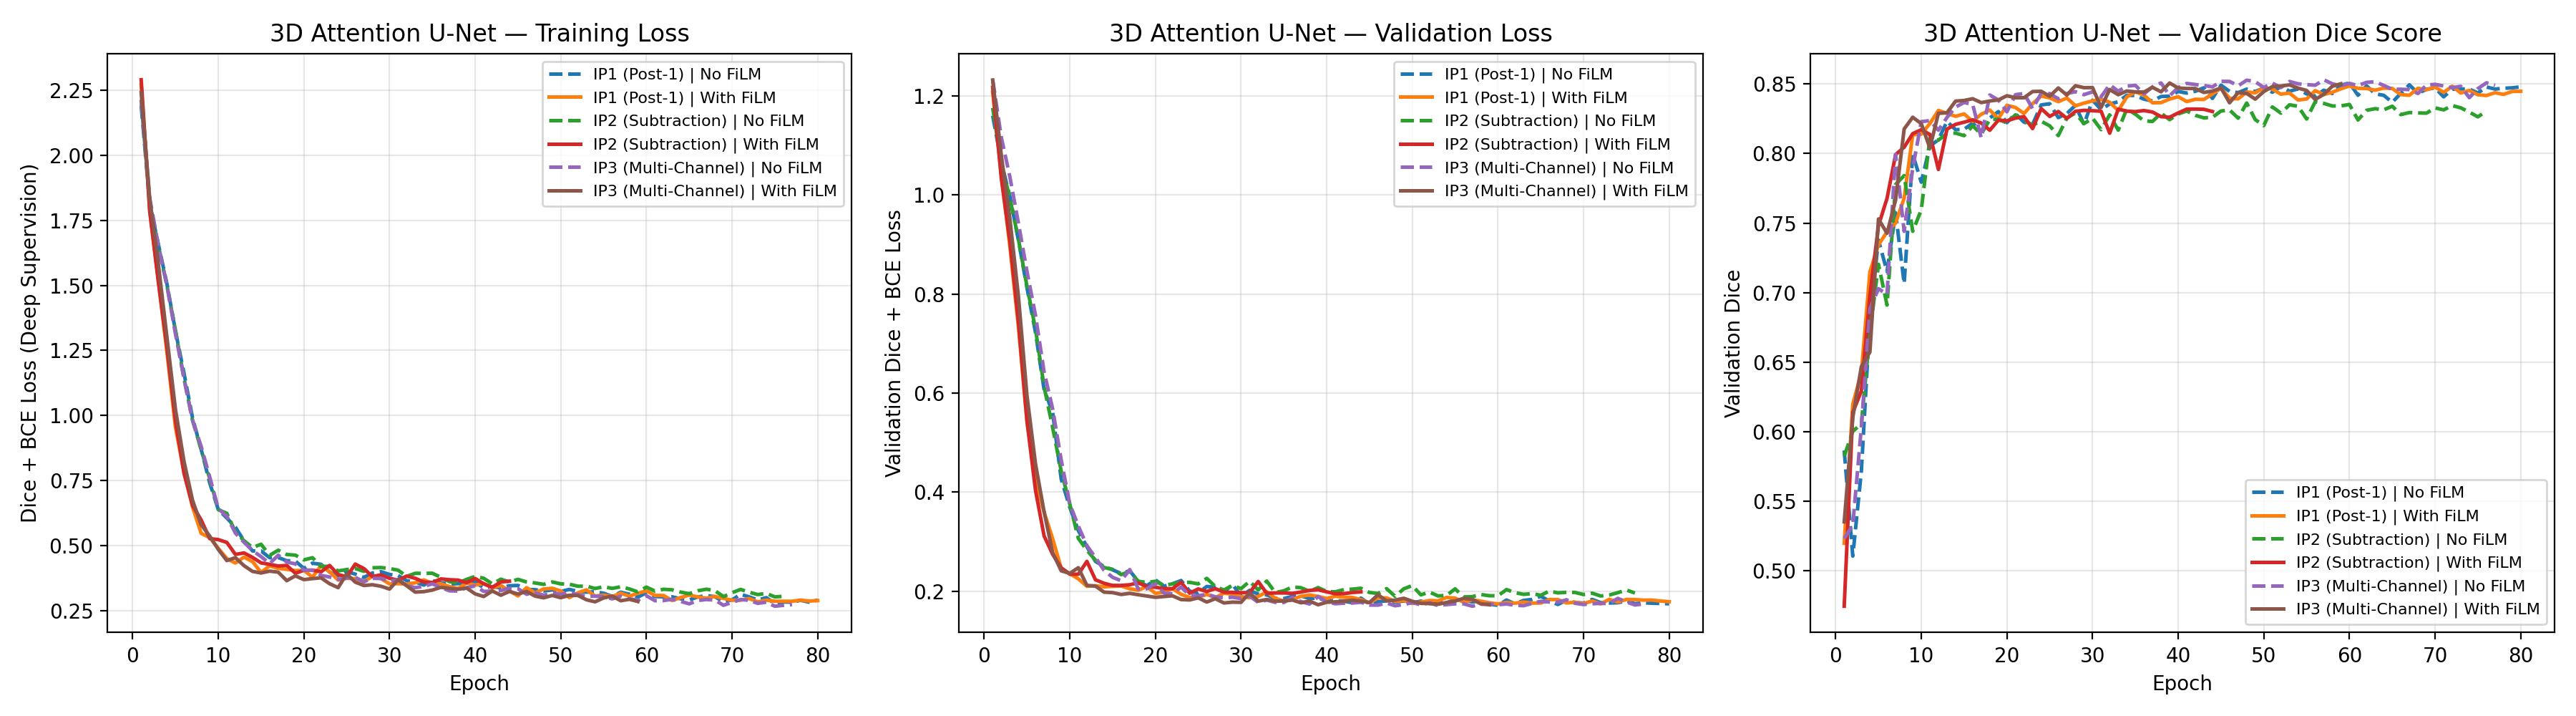

In [6]:
# 6. Hiển thị bảng tổng hợp kết quả Ablation và biểu đồ Learning Curves của TV3
from IPython.display import Image, display

summary_csv = OUTPUT_ROOT / "tables" / "tv3_week2_ablation_summary.csv"
curve_png = OUTPUT_ROOT / "figures" / "tv3_week2_learning_curves.png"

if summary_csv.is_file():
    df_res = pd.read_csv(summary_csv)
    display(df_res)

if curve_png.is_file():
    display(Image(filename=str(curve_png)))

In [7]:
# 7. Drive Sync An Toàn & Tự Động Ngắt Kết Nối (Bảo vệ Checkpoint + Không Mất Units Oan)
import os
import time
import traceback
from google.colab import runtime

print(">>> Đang hoàn tất tiến trình, đồng bộ dữ liệu xuống Google Drive...")
try:
    # 1. Ép hệ thống xả toàn bộ bộ đệm file xuống Google Drive FUSE
    os.sync()
    time.sleep(15)  # Cho 15s để daemon Google Drive đẩy hết các chunk dữ liệu cuối cùng lên cloud

    # 2. Kiểm tra nhanh các file best.pt đã lưu được trên Drive
    ckpt_dir = OUTPUT_ROOT / "checkpoints" / "tv3_week2"
    ckpts = sorted(list(ckpt_dir.glob("*/best.pt")))
    print(f"\nĐã ghi nhận {len(ckpts)} checkpoint best.pt trên Drive:")
    for cp in ckpts:
        sz_mb = round(cp.stat().st_size / (1024 ** 2), 2)
        print(f"  + {cp.parent.name}/best.pt ({sz_mb} MB)")
    print("\n>>> ĐỒNG BỘ GOOGLE DRIVE HOÀN TẤT AN TOÀN 100%!")
except Exception as exc:
    print(f"[CẢNH BÁO KHI SYNC]: {exc}")
    traceback.print_exc()
finally:
    # Khối finally LUÔN LUÔN được thực thi để ngắt runtime, không bao giờ để máy chạy rỗng mất Compute Units
    print("\n>>> TIẾN TRÌNH KẾT THÚC. TỰ ĐỘNG GIẢI PHÓNG GPU A100 ĐỂ TIẾT KIỆM COMPUTE UNITS...")
    time.sleep(5)
    runtime.unassign()

>>> Đang hoàn tất tiến trình, đồng bộ dữ liệu xuống Google Drive...

Đã ghi nhận 6 checkpoint best.pt trên Drive:
  + run07_M2_IP1_post1_no_film/best.pt (311.11 MB)
  + run08_M2_IP1_post1_film/best.pt (314.64 MB)
  + run09_M2_IP2_sub_no_film/best.pt (311.11 MB)
  + run10_M2_IP2_sub_film/best.pt (314.64 MB)
  + run11_M2_IP3_multi_no_film/best.pt (311.13 MB)
  + run12_M2_IP3_multi_film/best.pt (314.66 MB)

>>> ĐỒNG BỘ GOOGLE DRIVE HOÀN TẤT AN TOÀN 100%!

>>> TIẾN TRÌNH KẾT THÚC. TỰ ĐỘNG GIẢI PHÓNG GPU A100 ĐỂ TIẾT KIỆM COMPUTE UNITS...
